# Deep Hedging : reproduction et mise à l'épreuve sur données financières réelles

**Projet de Deep Learning — M2 ISF**

**Référence :** Brugière, P. & Turinici, G. (2025), *Model-Free Deep Hedging with Transaction Costs and Light Data Requirements*.

## Objectif du projet

Nous étudions la couverture dynamique d'un call européen à l'aide d'un réseau de neurones.

Dans le modèle de Black-Scholes, une stratégie de couverture continue et autofinancée permet de répliquer parfaitement le payoff d'une option, sous les hypothèses du modèle.

En pratique, les transactions sont discrètes et engendrent des coûts. La réplication parfaite n'est alors plus garantie.

L'article de Brugière et Turinici propose d'apprendre une stratégie de couverture à partir d'un nombre limité de trajectoires de prix, en minimisant la dispersion du coût final de couverture.

Notre projet poursuit trois objectifs :

1. **Reproduction :** implémenter l'approche de deep hedging présentée dans l'article et la comparer au delta hedging classique.
2. **Validation empirique :** appliquer les stratégies obtenues à des trajectoires financières historiques, puis évaluer leurs performances hors échantillon.
3. **Analyse de robustesse :** étudier l'effet des coûts de transaction, du choix des données d'entraînement et des caractéristiques du réseau.

Nous chercherons notamment à déterminer si le deep hedging apporte une amélioration mesurable par rapport aux méthodes classiques dans un environnement de trading plus réaliste.

## Méthodologie

Nous commencerons par simuler le prix d'un sous-jacent selon un mouvement brownien géométrique, afin de reproduire le cadre de l'article.

Nous implémenterons ensuite les stratégies de Black-Scholes, de Leland et le modèle de deep hedging en PyTorch.

Enfin, nous évaluerons les stratégies sur des données financières historiques avec différents scénarios de coûts de transaction.

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch 

from scipy.stats import norm

# --------------------------------------------------
# Reproductibilité
# --------------------------------------------------

SEED = 42

np.random.seed(SEED)
torch.manual_seed(SEED)

# --------------------------------------------------
# Paramètres du mouvement brownien géométrique
# --------------------------------------------------

S0 = 1.0          # Prix initial du sous-jacent
mu = 0.05         # Rendement instantané annuel sous P
sigma = 0.20      # Volatilité annuelle
r = 0.0           # Taux sans risque (cas des tableaux du papier)
T = 0.25          # Maturité : 3 mois en années

N_STEPS = 30      # Nombre d'intervalles de temps
N_TRAIN = 256     # Nombre de trajectoires d'entraînement
N_TEST = 256      # Nombre de trajectoires de test

K = S0            # Call at-the-money initialement
dt = T / N_STEPS  # Durée d'un pas de temps

print(f"Pas de temps : {dt:.6f} année")
print(f"Trajectoires d'entraînement : {N_TRAIN}")
print(f"Trajectoires de test : {N_TEST}")
print(f"Strike : {K}")


Pas de temps : 0.008333 année
Trajectoires d'entraînement : 256
Trajectoires de test : 256
Strike : 1.0


In [2]:

def simulate_gbm(
    n_paths,
    n_steps,
    S0,
    mu,
    sigma,
    T,
    seed
):
    """
    Simule des trajectoires de mouvement brownien géométrique.

    Returns
    -------
    paths : np.ndarray, shape (n_paths, n_steps + 1)
        Chaque ligne est une trajectoire complète de prix.
    """

    rng = np.random.default_rng(seed)
    dt = T / n_steps

    # Incréments browniens standardisés indépendants
    Z = rng.standard_normal(size=(n_paths, n_steps))

    # Log-rendements sur chaque intervalle
    log_returns = (
        (mu - 0.5 * sigma**2) * dt
        + sigma * np.sqrt(dt) * Z
    )

    # On ajoute la valeur initiale : log(S0/S0) = 0
    log_paths = np.concatenate(
        [np.zeros((n_paths, 1)),
         np.cumsum(log_returns, axis=1)],
        axis=1
    )

    paths = S0 * np.exp(log_paths)

    return paths


# Deux datasets indépendants
train_paths = simulate_gbm(
    N_TRAIN, N_STEPS, S0, mu, sigma, T, seed=42
)

test_paths = simulate_gbm(
    N_TEST, N_STEPS, S0, mu, sigma, T, seed=2026
)

print("Dimensions train :", train_paths.shape)
print("Dimensions test  :", test_paths.shape)

# Vérifications élémentaires
assert train_paths.shape == (256, 31)
assert np.all(train_paths > 0)
assert np.allclose(train_paths[:, 0], S0)


Dimensions train : (256, 31)
Dimensions test  : (256, 31)


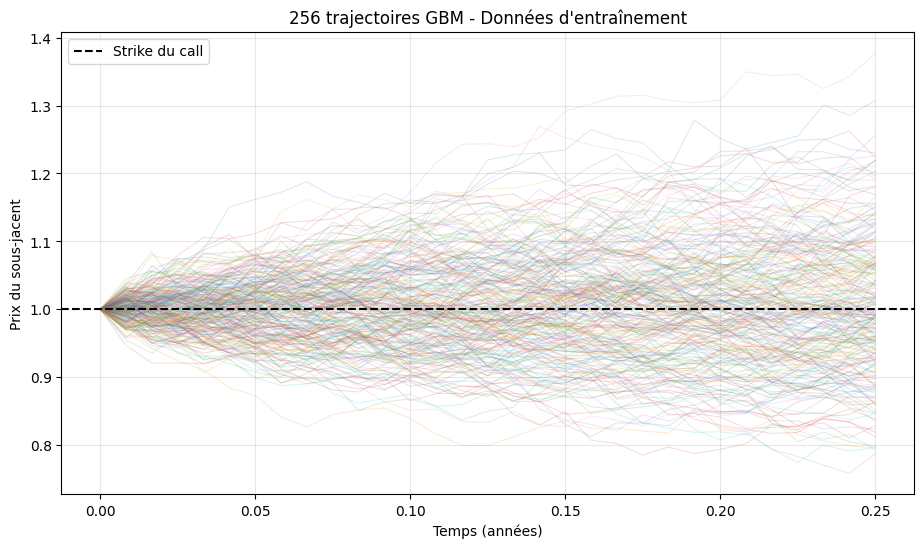

In [ ]:

# Dates exprimées en années
times = np.linspace(0, T, N_STEPS + 1)

plt.figure(figsize=(11, 6))

# Affichage des trajectoires d'entraînement
for path in train_paths:
    plt.plot(times, path, alpha=0.18, linewidth=0.7)

plt.axhline(
    K,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Strike du call"
)

plt.xlabel("Temps (années)")
plt.ylabel("Prix du sous-jacent")
plt.title("256 trajectoires GBM - Données d'entraînement")
plt.legend()
plt.grid(alpha=0.3)
plt.show()
